In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import math
device = "cuda"
print(torch.cuda.get_device_name(0))

Tesla T4


100%|██████████| 9.91M/9.91M [00:00<00:00, 36.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.14MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 8.54MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.46MB/s]


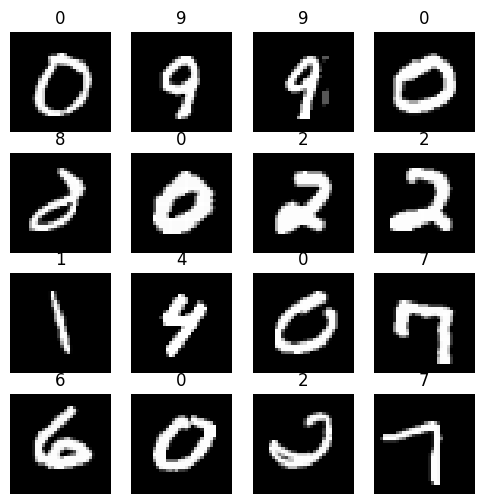

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Pad(2), 
    transforms.Lambda(lambda x: x * 2 - 1)
])
ds = datasets.MNIST(root = "/kaggle/temp/mnist", transform = transform, download = True)
img, label = ds[0]
loader = DataLoader(ds, batch_size = 128, shuffle = True)
x, y = next(iter(loader))
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for i in range(16):
    ax = axes.flatten()[i]
    ax.imshow(x[i, 0], cmap = "gray")
    ax.set_title(y[i].item())
    ax.axis("off")
plt.show()

tensor(0.6016)
tensor(0.6400)
tensor(0.7253)
tensor(0.8051)
tensor(0.8799)
tensor(0.9518)
tensor(0.9911)


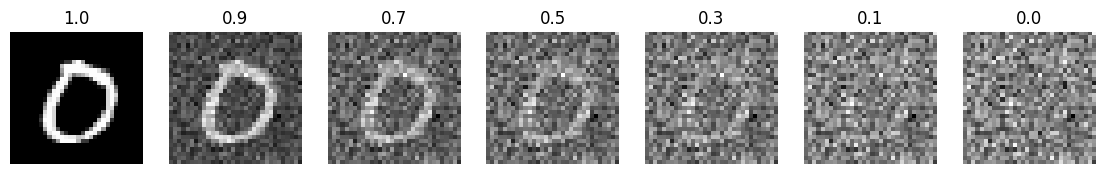

In [3]:
clean = x[0]
noise = torch.randn_like(clean)
fig, axes = plt.subplots(1, 7, figsize=(14, 2))
for i, a in enumerate([1.0, 0.9, 0.7, 0.5, 0.3, 0.1, 0.0]):
    noisy = math.sqrt(a) * clean + math.sqrt(1 - a) * noise
    axes[i].imshow(noisy[0], cmap = "gray")
    axes[i].set_title(a)
    axes[i].axis("off")
    print(noisy.std())
plt.show()

tensor(0.9999) tensor(0.0786) tensor(4.0358e-05)


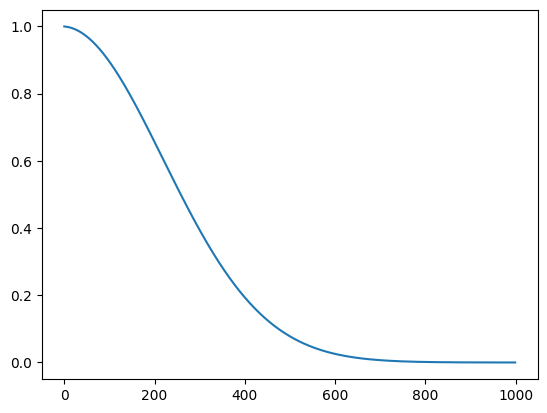

In [4]:
T = 1000
betas = torch.linspace(0.0001, 0.02, T)
alphas = 1 - betas
alpha_bar =  torch.cumprod(alphas, dim = 0)
print(alpha_bar[0], alpha_bar[499], alpha_bar[999])
plt.plot(alpha_bar)
plt.show()

torch.Size([8, 1, 32, 32])


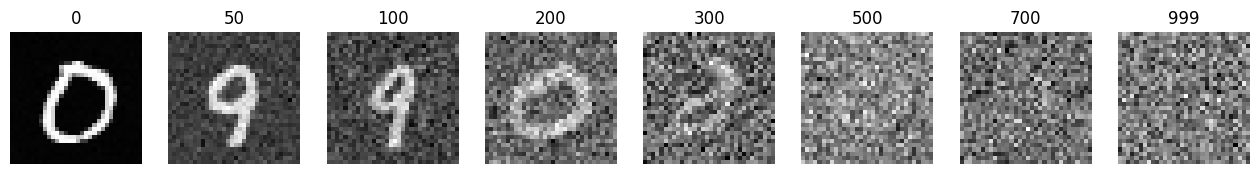

In [5]:
def add_noise(x0, t):
    noise = torch.randn_like(x0)
    a = alpha_bar[t]
    a = a.view(-1, 1, 1, 1)
    noisy = torch.sqrt(a) * x0 + torch.sqrt(1 - a) * noise
    return noisy, noise
t = torch.tensor([0, 50, 100, 200, 300, 500, 700, 999])
noisy, noise = add_noise(x[:8], t)
print(noisy.shape)
fig, axes = plt.subplots(1, 8, figsize = (16, 2))
for i in range(8):
    axes[i].imshow(noisy[i, 0], cmap = "gray")
    axes[i].set_title(t[i].item())
    axes[i].axis("off")
plt.show()